# Comparing mantispy's gene tests on a real screen

In a pooled CRISPR screen each gene is knocked out by a few guides, and each guide marks its own cells.
mantispy offers several ways to turn a gene's guides into one call.
On a real screen, this page shows how they compare on known biology, on fake genes, with each other and in speed, and how to check any single call.

{func}`~mantispy.tl.bootstrap_features` first asks of each guide how far its cells lie from the cells of non-targeting guides, and then combines the guides of a gene in one of four ways, set by `method`:

- `"stouffer"`, the default, adds up the evidence from all guides of a gene, giving guides with more cells more weight;
- `"order"`, the strict majority, calls a gene only if most of its guides agree;
- `"fisher"` calls a gene when any one guide is strong enough;
- `"median"` tests the median of the guides' medians.

The data are Aconcagua, Brieflow's reanalysis {cite:p}`Di_Bernardo_2026` of an optical pooled screen in HeLa cells {cite:p}`Funk_2022`, whose per-cell table is public.
The page uses plate 1, and all eight plates for the known biology and the run times.
To run it on your own screen, adapt `to_cells` below, and see {func}`~mantispy.io.from_dataframe` for the table it expects.

In [1]:
import re
import time
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm, on import

In [2]:
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
import pyarrow.fs
import pyarrow.parquet as pq
from scipy import stats

import mantispy as mt

CELL_TABLE = "ops-explorer-public/aconcagua/aconcagua/cell_data.parquet"
CELL_TABLE_BYTES = 323_471_309_291  # the size of the table this page was run on, so a changed table fails loudly
PLATE = 1

# Brieflow's published gene table, shared with the optical pooled screens case study, for the 76 features it tested
published = ad.read_h5ad(
    pooch.retrieve(
        "https://exampledata.scverse.org/mantispy/aconcagua/aconcagua_brieflow_interphase.h5ad",
        known_hash="sha256:f55756939edc8ddf108092d88c4efe248765b4db4ec39322d4b4a988e04af929",
        fname="aconcagua_brieflow_interphase.h5ad",
        path=mt.settings.cache_dir,
    )
)
FEATURES = list(published.var_names)


def read_plate(plate):
    """The interphase cells of one plate of the public Aconcagua cell table, in the features Brieflow tested."""
    path = mt.settings.cache_dir / f"aconcagua_plate{plate}_interphase.parquet"
    if path.exists():
        return pd.read_parquet(path)
    s3 = pyarrow.fs.S3FileSystem(anonymous=True, region="us-west-2")
    size = s3.get_file_info(CELL_TABLE).size
    if size != CELL_TABLE_BYTES:
        raise ValueError(f"the cell table is {size} bytes, not the {CELL_TABLE_BYTES} this page was run on")
    table = pq.ParquetFile(CELL_TABLE, filesystem=s3)
    plate_column = table.schema_arrow.names.index("plate")
    # the table is sorted by plate, so the row groups whose plate range covers the plate hold all of its cells
    groups = [
        i
        for i in range(table.metadata.num_row_groups)
        if (s := table.metadata.row_group(i).column(plate_column).statistics).min <= plate <= s.max
    ]
    columns = ["plate", "well", "barcode", "perturbation_id", "class", "is_control"]
    cells = table.read_row_groups(groups, columns=columns + FEATURES).to_pandas()
    cells = cells[(cells["plate"] == plate) & (cells["class"] == "Interphase") & cells["perturbation_id"].notna()]
    cells = cells.reset_index(drop=True)
    cells.to_parquet(path)
    return cells


raw = read_plate(PLATE)

In [3]:
BY_WELL = ["Metadata_Plate", "Metadata_Well"]


def to_cells(raw):
    """One plate's cells as an AnnData object, normalized by its wells' non-targeting cells into the layer "mad"."""
    control = raw["is_control"].astype(bool).to_numpy()
    plate_cells = mt.io.from_dataframe(
        pd.DataFrame(
            {
                "Metadata_Plate": raw["plate"].astype(str),
                "Metadata_Well": raw["well"].astype(str),
                "Metadata_sgRNA": raw["barcode"].astype(str),
                "Metadata_Gene": np.where(control, "nontargeting", raw["perturbation_id"].astype(str)),
                "Metadata_Control_Type": np.where(control, "negcon", "treatment"),
                **{name: raw[name].astype(np.float32) for name in FEATURES},
            }
        ),
        resolution="object",
    )
    mt.pp.normalize(plate_cells, method="mad_robustize", by=BY_WELL, reference="negcon", key_added="mad")
    return plate_cells


cells = to_cells(raw)
del raw
assert cells.n_obs == 4_406_575, cells.n_obs  # the plate's interphase cells with a guide when this page was run

obs = cells.obs
control = (obs["Metadata_Control_Type"] == "negcon").to_numpy()
cells_per_guide = obs.groupby("Metadata_sgRNA", observed=True).size()
nt_guides = np.sort(obs.loc[control, "Metadata_sgRNA"].unique())
gene_guides = obs.loc[~control, "Metadata_sgRNA"].unique()
guides_per_gene = obs.loc[~control].groupby("Metadata_Gene", observed=True)["Metadata_sgRNA"].nunique()
print(f"{cells.n_obs:,} cells, {cells.n_vars} features, {obs['Metadata_Well'].nunique()} wells")
print(f"{guides_per_gene.size:,} genes, by guides per gene: {guides_per_gene.value_counts().sort_index().to_dict()}")
print(f"{len(nt_guides)} non-targeting guides, median {cells_per_guide[nt_guides].median():.0f} cells each")
print(f"{len(gene_guides):,} gene guides, median {cells_per_guide[gene_guides].median():.0f} cells each")

4,406,575 cells, 76 features, 6 wells
5,049 genes, by guides per gene: {3: 11, 4: 5038}
250 non-targeting guides, median 362 cells each
20,185 gene guides, median 201 cells each


In [4]:
BAGEL = "https://raw.githubusercontent.com/hart-lab/bagel/53388adbb4fb0931e5c9dda135502be19e4555f0"
HASHES = {
    "CEGv2.txt": "sha256:1b1df46f829e2c47dc8a4c164f60f5f1dc67513bafba7d8b9609421e0c75d27e",
    "NEGv1.txt": "sha256:18a6b37a8f182a1bf501548e6b28fe4fcef02fcd296f873ef500a21eeb433739",
}
lists = {
    name: set(
        pd.read_csv(
            pooch.retrieve(f"{BAGEL}/{name}", known_hash=known, fname=f"bagel_{name}", path=mt.settings.cache_dir),
            sep="\t",
        )["GENE"]
    )
    for name, known in HASHES.items()
}
screened = set(guides_per_gene.index)
ESSENTIAL = screened & lists["CEGv2.txt"]
NONESSENTIAL = screened & lists["NEGv1.txt"]
OLFACTORY = {gene for gene in screened if re.fullmatch(r"OR\d+[A-Z]+\d+\w*", gene)}
print(
    f"screened: {len(ESSENTIAL)} core essential genes, {len(NONESSENTIAL)} non-essential genes, "
    f"{len(OLFACTORY)} olfactory-receptor genes"
)

screened: 661 core essential genes, 82 non-essential genes, 29 olfactory-receptor genes


The cell below runs the four tests on plate 1, every gene in every feature.

In [5]:
# Stouffer, the default, runs last, so that guide_qc can read it further down
METHODS = {"strict majority": "order", "Fisher": "fisher", "median": "median", "Stouffer": "stouffer"}
COLORS = {"Stouffer": "tab:orange", "strict majority": "tab:purple", "Fisher": "tab:green", "median": "tab:blue"}
for method in METHODS.values():
    mt.tl.bootstrap_features(cells, layer="mad", method=method, key_added=method)


def best_scores(table):
    """Each gene's smallest p-value over the features, as -log10."""
    return -np.log10(np.maximum(table.groupby("group", observed=True)["pvalue"].min(), 1e-300))


def called_genes(table):
    """Whether each gene is called (q < 0.05) in at least one feature."""
    return table.groupby("group", observed=True)["qvalue"].min() < 0.05


best = pd.DataFrame({name: best_scores(cells.uns["mantispy"][method]) for name, method in METHODS.items()})
called = pd.DataFrame({name: called_genes(cells.uns["mantispy"][method]) for name, method in METHODS.items()})
print(f"genes called in at least one feature, of {len(called):,}:")
for name in METHODS:
    print(f"  {name}: {int(called[name].sum()):,}")

genes called in at least one feature, of 5,049:
  strict majority: 2,718
  Fisher: 2,705
  median: 2,462
  Stouffer: 2,778


## Do the tests agree?

Each dot below is one gene, placed by its strongest feature under Stouffer and under one of the other tests.
A dot on the dashed line means the two tests agree on how strong the gene is.

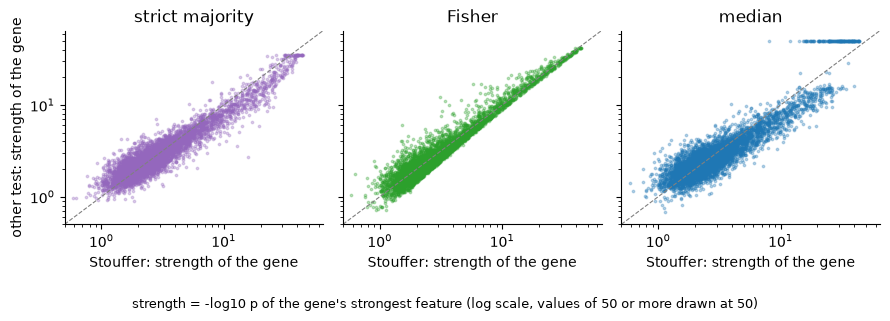

genes drawn at the cap of 50: strict majority 0, Fisher 0, median 141, Stouffer 0
strict majority: rank correlation with Stouffer 0.88, genes called by Stouffer only 441, by strict majority only 381
Fisher: rank correlation with Stouffer 0.93, genes called by Stouffer only 345, by Fisher only 272
median: rank correlation with Stouffer 0.84, genes called by Stouffer only 641, by median only 325


In [6]:
others = [name for name in METHODS if name != "Stouffer"]
CAP = 50  # strengths above this are drawn at it, so that genes at p = 0 don't stretch the axes
shown = best.clip(upper=CAP)
fig, axes = plt.subplots(1, 3, figsize=(9, 3.2), sharex=True, sharey=True)
for ax, name in zip(axes, others, strict=True):
    ax.scatter(shown["Stouffer"], shown[name], s=3, alpha=0.3, color=COLORS[name], rasterized=True)
    ax.axline((1, 1), (10, 10), color="0.5", lw=0.8, ls="--")
    ax.set(xscale="log", yscale="log", xlim=(0.5, CAP * 1.3), ylim=(0.5, CAP * 1.3))
    ax.set(title=name, xlabel="Stouffer: strength of the gene")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("other test: strength of the gene")
fig.supxlabel(
    f"strength = -log10 p of the gene's strongest feature (log scale, values of {CAP} or more drawn at {CAP})",
    fontsize=9,
)
fig.tight_layout()
plt.show()
print(f"genes drawn at the cap of {CAP}: " + ", ".join(f"{name} {int((best[name] >= CAP).sum())}" for name in METHODS))

for name in others:
    rho = stats.spearmanr(best["Stouffer"], best[name]).statistic
    only_stouffer = int((called["Stouffer"] & ~called[name]).sum())
    only_other = int((called[name] & ~called["Stouffer"]).sum())
    print(
        f"{name}: rank correlation with Stouffer {rho:.2f}, genes called by Stouffer only {only_stouffer}, by {name} only {only_other}"
    )

Stouffer agrees most with Fisher (rank correlation 0.93) and least with the median test (0.84), and the dots spread most for weak genes, where the tests disagree on which genes pass the cut.
For example, of the 5,049 genes Stouffer calls 441 that the strict majority doesn't, and the strict majority calls 381 that Stouffer doesn't.
The median test gives 141 genes a p-value of 1e-50 or smaller, the row at the top of its panel, where Stouffer rates the same genes far lower.

## Do they find known biology?

Knocking out a gene that cells need to grow should change how they look, and knocking out one they don't need mostly shouldn't.
The curve below follows each test as it calls more genes, from its strongest gene down: the share of known essential genes it finds (CEGv2, {cite:t}`Hart_2017`) against the share of known non-essential genes it ranks as high along the way (NEGv1, {cite:t}`Hart_2014`).
A curve towards the top left is better, and the dashed diagonal is a test that guesses.

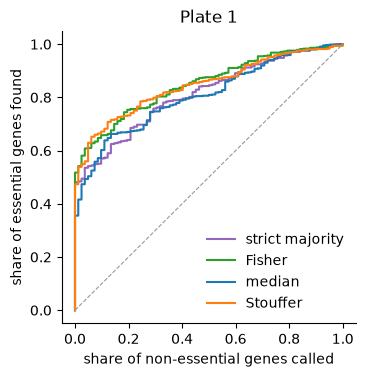

strict majority: AUC 0.813
Fisher: AUC 0.849
median: AUC 0.806
Stouffer: AUC 0.846


In [7]:
def auc(scores, positive, negative):
    """The probability that a positive gene scores higher than a negative one."""
    return stats.mannwhitneyu(scores[positive], scores[negative]).statistic / (len(positive) * len(negative))


ESSENTIAL_GENES, NONESSENTIAL_GENES = np.array(sorted(ESSENTIAL)), np.array(sorted(NONESSENTIAL))
fig, ax = plt.subplots(figsize=(3.8, 3.8))
for name in METHODS:
    scores = best[name]
    thresholds = np.unique(scores)[::-1]
    found = [(scores[ESSENTIAL_GENES] >= t).mean() for t in thresholds]
    wrong = [(scores[NONESSENTIAL_GENES] >= t).mean() for t in thresholds]
    ax.plot([0, *wrong, 1], [0, *found, 1], color=COLORS[name], lw=1.5, label=name)
ax.plot([0, 1], [0, 1], color="0.6", lw=0.8, ls="--")
ax.set(xlabel="share of non-essential genes called", ylabel="share of essential genes found", title="Plate 1")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.show()
for name in METHODS:
    print(f"{name}: AUC {auc(best[name], ESSENTIAL_GENES, NONESSENTIAL_GENES):.3f}")

The area under each curve, the AUC, sums it up from 0.5 for guessing to 1 for perfect, and the cell below plots it for each of the eight plates.

eight plates: 78 min


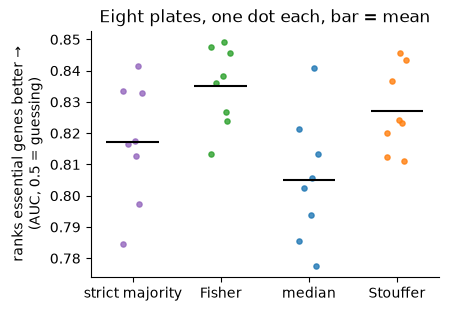

strict majority: mean AUC 0.817, best of the four tests on 1 of 8 plates
Fisher: mean AUC 0.835, best of the four tests on 6 of 8 plates
median: mean AUC 0.805, best of the four tests on 0 of 8 plates
Stouffer: mean AUC 0.827, best of the four tests on 1 of 8 plates


In [8]:
def compare_plate(plate):
    """Each test's AUC and run time on one plate."""
    plate_cells = to_cells(read_plate(plate))
    row = {"cells": plate_cells.n_obs}
    for name, method in METHODS.items():
        start = time.perf_counter()
        mt.tl.bootstrap_features(plate_cells, layer="mad", method=method, key_added=method)
        row[f"seconds, {name}"] = time.perf_counter() - start
        scores = best_scores(plate_cells.uns["mantispy"][method])
        row[f"AUC, {name}"] = auc(scores, ESSENTIAL_GENES, NONESSENTIAL_GENES)
    return row


start = time.perf_counter()
plates = pd.DataFrame({plate: compare_plate(plate) for plate in range(1, 9)}).T
print(f"eight plates: {(time.perf_counter() - start) / 60:.0f} min")
assert plates.loc[1, "cells"] == 4_406_575

fig, ax = plt.subplots(figsize=(4.5, 3.2))
jitter = np.random.default_rng(0).uniform(-0.12, 0.12, len(plates))
for i, name in enumerate(METHODS):
    values = plates[f"AUC, {name}"].astype(float)
    ax.scatter(i + jitter, values, s=14, color=COLORS[name], alpha=0.8)
    ax.hlines(values.mean(), i - 0.3, i + 0.3, color="black", lw=1.5)
ax.set_xticks(range(len(METHODS)), list(METHODS))
ax.set(ylabel="ranks essential genes better →\n(AUC, 0.5 = guessing)", title="Eight plates, one dot each, bar = mean")
ax.spines[["top", "right"]].set_visible(False)
plt.show()
for name in METHODS:
    values = plates[f"AUC, {name}"].astype(float)
    print(
        f"{name}: mean AUC {values.mean():.3f}, best of the four tests on {int((plates[[f'AUC, {m}' for m in METHODS]].astype(float).idxmax(axis=1) == f'AUC, {name}').sum())} of {len(plates)} plates"
    )

Fisher and Stouffer rank essential genes best, with a mean AUC over the eight plates of 0.835 for Fisher and 0.827 for Stouffer, against 0.817 for the strict majority and 0.805 for the median test.
Plates differ by about as much as the tests do, but Fisher is the best of the four on 6 of 8 plates, so its lead holds on most plates.

## Do they call fake genes?

A good test should call almost none of a set of fake genes made from non-targeting guides.
The cell below makes 30 fake genes of four non-targeting guides each, gives each guide at most as many cells as a real guide drawn at random, and tests them in every feature.

22,007 cells in 30 pseudo-genes of 4 non-targeting guides
130 non-targeting guides stay as the controls


strict majority: 4.3% of fake-gene p-values below 0.05, where a perfect test gives 5%
Fisher: 3.3% of fake-gene p-values below 0.05, where a perfect test gives 5%
median: 3.3% of fake-gene p-values below 0.05, where a perfect test gives 5%
Stouffer: 3.6% of fake-gene p-values below 0.05, where a perfect test gives 5%


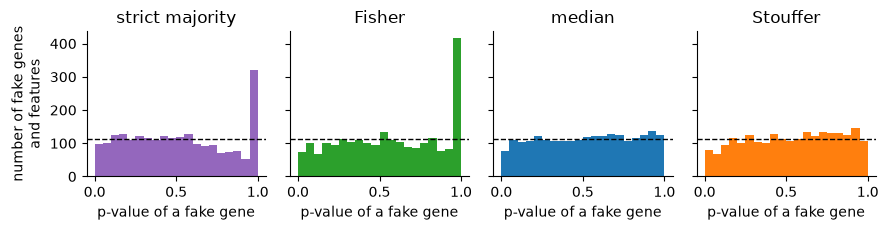

In [9]:
def pseudo_genes(plate_cells, seed=0):
    """The plate with 120 non-targeting guides held out as 30 pseudo-genes of four, normalized on the other 130."""
    plate_obs = plate_cells.obs
    is_control = (plate_obs["Metadata_Control_Type"] == "negcon").to_numpy()
    per_guide = plate_obs.groupby("Metadata_sgRNA", observed=True).size()
    rng = np.random.default_rng(seed)
    held_out = rng.choice(np.sort(plate_obs.loc[is_control, "Metadata_sgRNA"].unique()), size=120, replace=False)
    guide = plate_obs["Metadata_sgRNA"].astype(str).to_numpy()
    gene = plate_obs["Metadata_Gene"].astype(str).to_numpy().copy()
    control_type = plate_obs["Metadata_Control_Type"].astype(str).to_numpy().copy()
    keep = np.ones(plate_cells.n_obs, dtype=bool)
    sizes = per_guide[plate_obs.loc[~is_control, "Metadata_sgRNA"].unique()].to_numpy()
    for i, held in enumerate(held_out):
        rows = np.flatnonzero(guide == held)
        size = int(rng.choice(sizes))  # as many cells as a gene guide drawn at random
        if rows.size > size:
            keep[rng.choice(rows, size=rows.size - size, replace=False)] = False
        gene[rows] = f"PSEUDO{i // 4}"
        control_type[rows] = "treatment"
    held = plate_cells[keep].copy()
    held.obs["Metadata_Gene"] = gene[keep]
    held.obs["Metadata_Control_Type"] = control_type[keep]
    mt.pp.normalize(held, method="mad_robustize", by=BY_WELL, reference="negcon", key_added="mad")
    return held


calib = pseudo_genes(cells)
print(
    f"{calib.obs['Metadata_Gene'].str.startswith('PSEUDO').sum():,} cells in 30 pseudo-genes of 4 non-targeting guides"
)
print(f"{len(nt_guides) - 120} non-targeting guides stay as the controls")

for method in METHODS.values():
    mt.tl.bootstrap_features(calib, layer="mad", method=method, key_added=method)

fig, axes = plt.subplots(1, 4, figsize=(9, 2.4), sharey=True)
for ax, (name, method) in zip(axes, METHODS.items(), strict=True):
    table = calib.uns["mantispy"][method]
    p = table.loc[table["group"].str.startswith("PSEUDO"), "pvalue"].to_numpy()
    ax.hist(p, bins=20, range=(0, 1), color=COLORS[name])
    ax.axhline(p.size / 20, color="black", lw=1, ls="--")
    ax.set(title=name, xlabel="p-value of a fake gene")
    ax.spines[["top", "right"]].set_visible(False)
    print(f"{name}: {np.mean(p < 0.05):.1%} of fake-gene p-values below 0.05, where a perfect test gives 5%")
axes[0].set_ylabel("number of fake genes\nand features")
fig.tight_layout()
plt.show()

A perfect test gives fake genes a flat histogram at the dashed line, so a bar above the line at the left means false hits, and a bar below it means the test is cautious.
The spike at p = 1 for the strict majority and Fisher is expected and isn't a false hit, because a gene whose guides mostly move the other way gets p = 1.
All four tests give fewer fake-gene p-values below 0.05 than the 5% a perfect test gives, from 3.3% for Fisher and the median test to 4.3% for the strict majority, so on plate 1 none of them gives fake genes small p-values more often than chance, within the noise of 30 fake genes.

## What if a gene's guides disagree?

Guides of one gene can differ by more than chance, e.g. through off-target cuts.
The simulation below gives every guide its own large random shift in each of 20 features, and gives none of its 250 genes a real effect, so every call it makes is false.

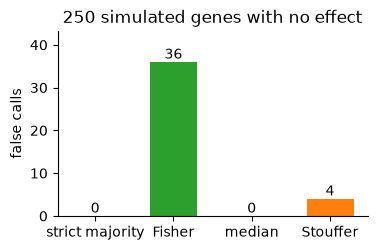

In [10]:
def simulate(sd, seed=5):
    """Cells of 200 control guides and 250 genes of 4 guides, each guide offset by its own N(0, sd) per feature."""
    rng = np.random.default_rng(seed)
    units = [("nontargeting", f"nt{i}") for i in range(200)]
    units += [(f"PSEUDO{g}", f"ps{g}_{s}") for g in range(250) for s in range(4)]
    blocks = [rng.normal(size=(400, 20)) + rng.normal(scale=sd, size=20) for _ in units]
    frame = pd.DataFrame(np.concatenate(blocks), columns=[f"Cells_Intensity_F{i}" for i in range(20)])
    frame.insert(0, "Metadata_Plate", "simulated")
    frame.insert(1, "Metadata_Gene", np.repeat([u[0] for u in units], 400))
    frame.insert(2, "Metadata_sgRNA", np.repeat([u[1] for u in units], 400))
    frame.insert(3, "Metadata_Control_Type", np.where(frame["Metadata_Gene"] == "nontargeting", "negcon", "treatment"))
    return mt.io.from_dataframe(frame, resolution="object")


sim = simulate(0.3)
false_calls = {}
for name, method in METHODS.items():
    mt.tl.bootstrap_features(sim, key_added=method, method=method)
    false_calls[name] = int((sim.uns["mantispy"][method]["qvalue"] < 0.05).sum())

fig, ax = plt.subplots(figsize=(4, 2.4))
ax.bar(list(false_calls), list(false_calls.values()), color=[COLORS[name] for name in false_calls], width=0.6)
for i, count in enumerate(false_calls.values()):
    ax.text(i, count, str(count), ha="center", va="bottom")
ax.set(ylabel="false calls", title="250 simulated genes with no effect")
ax.margins(y=0.2)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Counting gene and feature pairs called at q < 0.05, Fisher makes 36 false calls and Stouffer 4, because one guide far from all the non-targeting guides can carry a gene for them, while the strict majority and the median test make none.
The shift is chosen to be large, and how far the guides of a real screen spread depends on its reagents, which {func}`~mantispy.pp.guide_qc` helps check.

## How long does each take?

The bars below give the median time each test took on a plate of the screen, and the dots the eight plates.

strict majority: median 35 s per plate
Fisher: median 34 s per plate
median: median 63 s per plate
Stouffer: median 34 s per plate


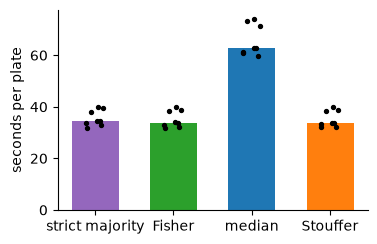

In [11]:
fig, ax = plt.subplots(figsize=(4, 2.6))
for i, name in enumerate(METHODS):
    seconds = plates[f"seconds, {name}"].astype(float)
    ax.bar(i, seconds.median(), color=COLORS[name], width=0.6)
    ax.scatter(i + jitter, seconds, s=8, color="black", zorder=3)
    print(f"{name}: median {seconds.median():.0f} s per plate")
ax.set_xticks(range(len(METHODS)), list(METHODS))
ax.set(ylabel="seconds per plate")
if plates[[f"seconds, {name}" for name in METHODS]].astype(float).to_numpy().max() > 20 * min(
    plates[f"seconds, {name}"].astype(float).median() for name in METHODS
):
    ax.set_yscale("log")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Stouffer, Fisher and the strict majority each take about 34 s per plate, and the median test about twice as long, 63 s.

With `median="midpoint"` the median test is Brieflow's gene test, so use it only to reproduce Brieflow's numbers, as [Coming from Brieflow](../tutorials/genetics/coming_from_brieflow.ipynb) does.

## Checking one call

{func}`~mantispy.pp.guide_qc` flags guides that look unreliable: inactive when its cells look like non-targeting cells, outlying when it lies far from the other guides of its gene, and thin when it has fewer than 10 cells.
It also marks each Stouffer call that rests on one guide.
The cell below picks the call on plate 1 that one guide carries most clearly, with that guide strongly active and the others near zero, and shows how each guide of the gene moves in the called feature and the gene's next strongest ones.
guide_qc judges each guide once over all features, and its verdict is in brackets after the guide.

Stouffer calls resting on one guide: 33 of 27,240


FBXO5 in nucleus_DAPI_integrated: one guide carries the Stouffer call


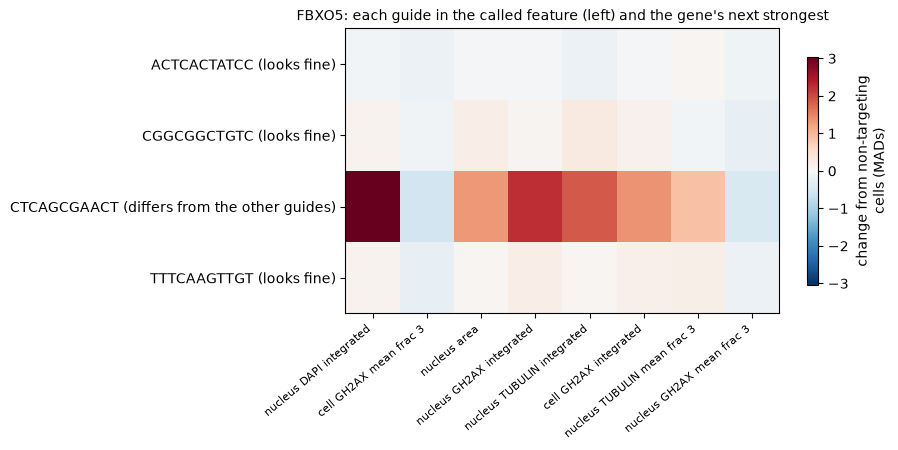

FBXO5, nucleus_DAPI_integrated: strict majority q = 0.343
FBXO5, nucleus_DAPI_integrated: Fisher q = 4.83e-05
FBXO5, nucleus_DAPI_integrated: median q = 0.422
FBXO5, nucleus_DAPI_integrated: Stouffer q = 0.0491


In [12]:
mt.pp.guide_qc(cells, key="stouffer")
flags = cells.uns["mantispy"]["guide_qc"]
summary = cells.uns["mantispy"]["guide_qc_summary"]
stouffer = cells.uns["mantispy"]["stouffer"]
single = summary[summary["single_guide"]].merge(stouffer[["group", "feature", "qvalue"]], on=["group", "feature"])
print(f"Stouffer calls resting on one guide: {len(single)} of {int((stouffer['qvalue'] < 0.05).sum()):,}")
guide_table = cells.uns["mantispy"]["stouffer_guides"]
outlying = flags.set_index(["group", "replicate"])["qc_guide_outlier_fail"]
inactive = flags.set_index(["group", "replicate"])["qc_guide_inactive_fail"]


def one_guide_call(call):
    """How cleanly one guide carries a call: its |effect| over the largest of its siblings', if guide_qc agrees."""
    rows = guide_table[(guide_table["group"] == call["group"]) & (guide_table["feature"] == call["feature"])]
    size = rows.set_index("replicate")["effect"].abs().sort_values(ascending=False)
    if len(size) < 3 or size.iloc[0] < 0.5:
        return 0.0
    strong, rest = size.index[0], size.index[1:]
    # guide_qc should flag the strong guide as outlying and none of the others
    clean = outlying[(call["group"], strong)] and not any(outlying[(call["group"], guide)] for guide in rest)
    return size.iloc[0] / size.iloc[1] if clean else 0.0


single["clarity"] = [one_guide_call(call) for _, call in single.iterrows()]
if (single["clarity"] > 0).any():
    pick = single.loc[single["clarity"].idxmax()]
    gene, feature = pick["group"], pick["feature"]
    print(f"{gene} in {feature}: one guide carries the Stouffer call")
else:
    # no clean one-guide call: a gene with two inactive guides that Stouffer calls and the strict majority misses
    two_inactive = inactive.groupby(level="group").sum().loc[lambda n: n >= 2].index
    order = cells.uns["mantispy"]["order"].set_index(["group", "feature"])["qvalue"]
    missed = stouffer[stouffer["group"].isin(two_inactive) & (stouffer["qvalue"] < 0.05)].copy()
    missed = missed[order.loc[list(zip(missed["group"], missed["feature"], strict=True))].to_numpy() >= 0.05]
    pick = missed.nsmallest(1, "qvalue").iloc[0]
    gene, feature = pick["group"], pick["feature"]
    print(f"{gene} in {feature}: two inactive guides, called by Stouffer and missed by the strict majority")

others_top = stouffer[(stouffer["group"] == gene) & (stouffer["feature"] != feature)].nsmallest(7, "pvalue")
top = [feature, *others_top["feature"]]
effects = (
    guide_table[(guide_table["group"] == gene) & guide_table["feature"].isin(top)]
    .pivot(index="replicate", columns="feature", values="effect")
    .loc[:, top]
)
NAMES = {
    "qc_guide_inactive_fail": "inactive",
    "qc_guide_outlier_fail": "differs from the other guides",
    "qc_guide_cells_fail": "too few cells",
}
verdict = {
    row["replicate"]: ", ".join(label for flag, label in NAMES.items() if row[flag]) or "looks fine"
    for _, row in flags[flags["group"] == gene].iterrows()
}
limit = np.abs(effects.to_numpy()).max()
fig, ax = plt.subplots(figsize=(7, 0.45 * len(effects) + 1.9))
image = ax.imshow(effects.to_numpy(), cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
ax.set_yticks(range(len(effects)), [f"{guide} ({verdict[guide]})" for guide in effects.index])
ax.set_xticks(range(len(top)), [name.replace("_", " ") for name in top], rotation=40, ha="right", fontsize=8)
ax.set_title(f"{gene}: each guide in the called feature (left) and the gene's next strongest", fontsize=10)
fig.colorbar(image, ax=ax, label="change from non-targeting\ncells (MADs)", shrink=0.8)
plt.show()
for name, method in METHODS.items():
    table = cells.uns["mantispy"][method]
    q = table.loc[(table["group"] == gene) & (table["feature"] == feature), "qvalue"].iloc[0]
    print(f"{gene}, {feature}: {name} q = {q:.3g}")

On plate 1, 33 of the 27,240 gene and feature pairs that Stouffer calls rest on one guide, and FBXO5 in nuclear DNA content (`nucleus_DAPI_integrated`) is the clearest of them.
Only one of its four guides moves, in several features, while the other three sit near zero, and guide_qc flags that guide as differing from the others.
Stouffer calls the gene in that feature at q = 0.0491, just under 0.05, Fisher calls it at q = 4.83e-05 because one strong guide is enough for it, and the strict majority and the median test don't call it (q = 0.343 and 0.422).
Treat such a call as a lead, and check whether the other guides cut before you trust it.

## What should I use?

- Use the default, `method="stouffer"`. It ranks essential genes nearly as well as Fisher, and one far-off guide carries it far less often (4 false calls in the simulation, against 36 for Fisher).
- Check the calls that rest on one guide with {func}`~mantispy.pp.guide_qc`, in the column `single_guide` of `uns["mantispy"]["guide_qc_summary"]`.
- Use `method="order"` if you think your guides are unreliable. One far-off guide can't carry a call, at the cost of ranking essential genes slightly worse.
- Use `method="median", median="midpoint"` only to match Brieflow's numbers.